# 02 — Бейзлайн «в лоб»

Задача раздела — получить **нижнюю планку качества**: число для сравнения
с более сложными моделями. Здесь нет ни агрегатов по всей
истории, ни кодировки через цель, ни взаимодействий — только самое прямолинейное,
что можно сделать с этими данными.

Рецепт «в лоб»:

1. **Одна строка на заявку.** Из истории берём последнюю запись (`rn = max`) со
   **всеми её сырыми колонками** — это последняя запись по номеру продукта, а не
   доказанное текущее состояние по всем полям. Среди этих колонок есть `rn` — номер
   последней записи, то есть длина истории заявки.
2. **Ярлыки остаются ярлыками.** Номера уровней не сравниваем: каждый уровень —
   отдельная категория.
3. **One-hot.** Каждому уровню — своя колонка `0/1`; редкие уровни (реже 500
   заявок на обучающей части) собраны в одну колонку `infrequent`.
4. **Логистическая регрессия.** Простая линейная модель на этих колонках.

Схема оценки на холдауте — как в `03`: обучение на `id < 2 000 000`, проверка — восемь блоков
по 125 000 заявок внутри `[2 000 000, 3 000 000)`. Матрицу по test не строим:
нижняя планка считается на блоках train, а test понадобится только финальной модели.

«В лоб» здесь означает следующее: **последняя запись как есть** — без агрегатов по
всей истории, без динамики между записями и без кодировки через цель. Единственная
сводная величина, которая остаётся в решении, — это `rn`: номер последней
записи равен длине истории заявки, и линейная модель использует его как отдельный
признак.

Свойства отправной точки: последняя запись — представление истории без агрегатов,
кодировка не использует цель, модель линейна. Разрыв с бустингом **согласуется**
с резервом в агрегатах по всей истории, кодировке уровней через цель и
взаимодействиях. При этом `02 → 03` меняет класс модели, признаки и кодировку; сравнение
0.6740 и 0.739142 относится к моделям, обученным на 2 млн заявок, поэтому разрыв
не изолирует вклад ни одного из изменений. Проверка этой гипотезы — в `03`.


In [1]:
import gc
import resource
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OneHotEncoder

STARTED = time.perf_counter()
SEED = 42  # random_state для LogisticRegression

RN_BASE = 1000        # id * 1000 + rn однозначен: максимум rn в train 58 (проверено в 01)
BATCH_ROWS = 250_000  # 250 000 строк на батч; в партиции около 2 млн строк
FIT_MAX = 2_000_000   # обучение — id < FIT_MAX
BLOCK_SIZE = 125_000  # проверка — восемь блоков внутри [2M, 3M)
MIN_FREQUENCY = 500   # уровни реже этого числа заявок собираются в infrequent
MAX_ITER = 1000       # лимит итераций логистической регрессии
EVAL_BLOCKS = [
    (FIT_MAX + index * BLOCK_SIZE, FIT_MAX + (index + 1) * BLOCK_SIZE) for index in range(8)
]


def find_repo_root() -> Path:
    """Корень репозитория ищем по pyproject.toml: ноутбук работает из любого каталога внутри репозитория."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise RuntimeError("не найден корень репозитория: pyproject.toml отсутствует вверх по дереву")


def part_key(path: Path) -> int:
    """Номер партиции из имени файла — чтобы порядок не зависел от лексикографии."""
    return int("".join(character for character in path.stem if character.isdigit()))


def peak_memory_gb() -> float:
    """Пик RSS процесса. macOS отдаёт байты, Linux — кибибайты."""
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return peak / 2**30 if sys.platform == "darwin" else peak / 2**20


def fmt(number: int) -> str:
    """Тысячи разделяем пробелом: числа форматируются одинаково во всех выводах."""
    return f"{number:,}".replace(",", " ")


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data" / "raw" / "data_for_competition"
TRAIN_PARTS = sorted((DATA_DIR / "train_data").glob("*.pq"), key=part_key)
TRAIN_TARGET = DATA_DIR / "train_target.csv"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

print(f"корень:          {REPO_ROOT.name}")
print(f"данные:          {DATA_DIR.relative_to(REPO_ROOT)}")
print(f"train-партиций:  {len(TRAIN_PARTS)}")
print(f"обучение:        id < {fmt(FIT_MAX)}")
eval_range = f"[{fmt(EVAL_BLOCKS[0][0])}, {fmt(EVAL_BLOCKS[-1][1])})"
print(f"проверка:        восемь блоков по 125 000 в {eval_range}")

корень:          kaggle-creditscore-alfa
данные:          data/raw/data_for_competition
train-партиций:  12
обучение:        id < 2 000 000
проверка:        восемь блоков по 125 000 в [2 000 000, 3 000 000)


## Одна строка на заявку

История — это 26,16 млн строк кредитных продуктов, но цель у заявки одна. Берём
**последнюю запись** каждой истории: в `03` показано, что `rn = max` — последняя
запись истории и она резко отличается от первой записи и промежуточных.

Читаем партиции батчами по 250 000 строк и оставляем последнюю строку каждой
заявки внутри батча. Стык батчей обрабатывается: если история продолжается в следующем
батче, `drop_duplicates(keep="last")` оставит именно последнюю строку. Попутно
проверяем, что файлы упорядочены по `(id, rn)`, — тогда «последняя строка» и
«максимальный `rn`» совпадают.


In [2]:
application_parts = []
part_rows = []
order_ok = True
last_key = -1
for part_path in TRAIN_PARTS:
    kept_rows = []
    history_rows = 0
    for batch in pq.ParquetFile(part_path).iter_batches(batch_size=BATCH_ROWS):
        block = batch.to_pandas().astype(np.int32)
        ids = block["id"].to_numpy()
        keys = ids.astype(np.int64) * RN_BASE + block["rn"].to_numpy()
        if keys[0] < last_key or np.any(np.diff(keys) < 0):
            order_ok = False
        last_key = int(keys[-1])
        # последняя строка каждой заявки внутри батча; строку на стыке батчей
        # вытеснит следующая при keep='last'
        is_last_in_batch = np.r_[ids[1:] != ids[:-1], True]
        kept_rows.append(block.loc[is_last_in_batch])
        history_rows += len(block)
        del block, ids, keys
    part = pd.concat(kept_rows, ignore_index=True).drop_duplicates("id", keep="last")
    kept_rows.clear()
    application_parts.append(part)
    part_rows.append({"файл": part_path.name, "строк истории": history_rows, "заявок": len(part)})
    _ = gc.collect()

applications = pd.concat(application_parts, ignore_index=True)
application_parts.clear()
applications = applications.drop_duplicates("id", keep="last")  # на стыке партиций дублей быть не должно
_ = gc.collect()

FEATURES = [name for name in applications.columns if name != "id"]
ids = applications["id"].to_numpy()
assert order_ok
assert np.array_equal(ids, np.arange(len(applications)))
assert "flag" not in FEATURES
assert int(applications["rn"].max()) < RN_BASE  # ключ id * RN_BASE + rn однозначен, пока rn < RN_BASE
assert applications["id"].is_unique
assert len(applications) == 3_000_000

print("партиции train:")
print(pd.DataFrame(part_rows).to_string(index=False))
print(f"\nстрок истории всего: {fmt(sum(row['строк истории'] for row in part_rows))}")
print(f"заявок (строк в таблице): {fmt(len(applications))}")
print("id уникален, идёт 0..N-1, файлы упорядочены по (id, rn): проверено ассертами")
print(f"признаков (без id): {len(FEATURES)}")

партиции train:
            файл  строк истории  заявок
 train_data_0.pq        1974724  250000
 train_data_1.pq        2107305  250000
 train_data_2.pq        2080508  250000
 train_data_3.pq        2112592  250000
 train_data_4.pq        2064110  250000
 train_data_5.pq        2150908  250000
 train_data_6.pq        2176452  250000
 train_data_7.pq        2222245  250000
 train_data_8.pq        2242615  250000
 train_data_9.pq        2284256  250000
train_data_10.pq        2296372  250000
train_data_11.pq        2450630  250000

строк истории всего: 26 162 717
заявок (строк в таблице): 3 000 000
id уникален, идёт 0..N-1, файлы упорядочены по (id, rn): проверено ассертами
признаков (без id): 60


## Метки

`flag` лежит отдельно, в `train_target.csv`. Привязываем метки по `id` и проверяем,
что метка нашлась для каждой из 3 млн заявок: пропущенная метка дала бы NaN
и ошибку при обучении.


In [3]:
targets = pd.read_csv(TRAIN_TARGET)
labels = targets.set_index("id")["flag"].reindex(ids)
labels = labels.to_numpy()
assert labels.size == len(applications)
assert not np.isnan(labels).any()  # пропущенная метка дала бы NaN и ошибку при обучении

print("train_target.csv:")
print(
    pd.DataFrame(
        {
            "строк": [len(targets)],
            "id уникален": [targets["id"].is_unique],
            "id min": [int(targets["id"].min())],
            "id max": [int(targets["id"].max())],
            "flag = 1": [int(targets["flag"].sum())],
        }
    ).to_string(index=False)
)
print("\nметка есть для каждой заявки: проверено ассертом")
fit_mask = ids < FIT_MAX
print(f"обучающая часть: {fmt(int(fit_mask.sum()))} заявок, проверочная: {fmt(int((~fit_mask).sum()))}")
print(f"доля flag=1 на обучении: {labels[fit_mask].mean():.4f}")
print("\nзаявок без метки нет; редкая цель (одна из двадцати восьми) — как в 01")

train_target.csv:
  строк  id уникален  id min  id max  flag = 1
3000000         True       0 2999999    106442

метка есть для каждой заявки: проверено ассертом
обучающая часть: 2 000 000 заявок, проверочная: 1 000 000
доля flag=1 на обучении: 0.0362

заявок без метки нет; редкая цель (одна из двадцати восьми) — как в 01


## One-hot: ярлыки — в колонки

Номер уровня — случайный ярлык (сноски `*` и `**` в словаре), поэтому превращаем его
в отдельную колонку `0/1`. Редкие уровни (реже `MIN_FREQUENCY` заявок) собираем в одну колонку
`infrequent`: иначе уровень с парой заявок получил бы собственный коэффициент,
неустойчивый при малом числе заявок.

Кодировщик обучается **только на `id < 2 000 000`** и затем применяется ко всем
заявкам. Это соответствует протоколу: если обучать его на всех строках, кодировщик
учитывал бы уровни проверочной части — это нарушение, хотя целевая переменная не
используется. Целевой утечки нет; эффект от невиданных уровней не измерен.
В текущем прогоне невиданных строк 16 — они попадают в `infrequent`.


In [4]:
encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=MIN_FREQUENCY,
    sparse_output=True,
    dtype=np.float32,
)
X_fit = encoder.fit_transform(applications.loc[fit_mask, FEATURES])
X_eval = encoder.transform(applications.loc[~fit_mask, FEATURES])
FEATURE_NAMES = encoder.get_feature_names_out(FEATURES)

# Невиданные уровни: значения eval-строк, которых нет в словаре, выученном на fit.
eval_features = applications.loc[~fit_mask, FEATURES]
unseen_rows = np.zeros(len(eval_features), dtype=bool)
unseen_pairs = []
for index, feature in enumerate(FEATURES):
    values = eval_features[feature].to_numpy()
    categories = encoder.categories_[index]
    found = np.clip(np.searchsorted(categories, values), 0, len(categories) - 1)
    unseen = categories[found] != values
    unseen_rows |= unseen
    for level in np.unique(values[unseen]):
        unseen_pairs.append(
            {
                "колонка": feature,
                "невиданный уровень": int(level),
                "строк": int((values[unseen] == level).sum()),
            }
        )

infrequent = int(sum("infrequent" in name for name in FEATURE_NAMES))
print(f"матрица обучения: {X_fit.shape[0]} x {X_fit.shape[1]} (спарс)")
print(f"матрица проверки: {X_eval.shape[0]} x {X_eval.shape[1]} (спарс)")
print(f"колонок после one-hot: {len(FEATURE_NAMES)}")
print(f"из них «сборная солянка» infrequent: {infrequent} — по одной на признак с редкими уровнями")
print(f"ненулевых на строку: {X_fit.nnz / X_fit.shape[0]:.0f} (по одному уровню на признак)")

print("\nневиданные уровни у eval-строк (пары «колонка × невиданный уровень»):")
if unseen_pairs:
    print(pd.DataFrame(unseen_pairs).to_string(index=False))
else:
    print("  нет — все уровни eval-строк встречались на обучении")
print(f"строк хотя бы с одним невиданным уровнем: {int(unseen_rows.sum())}")
print(f"строк, где ненулевых меньше числа признаков ({len(FEATURES)}): "
      f"{int((X_eval.getnnz(axis=1) < len(FEATURES)).sum())}")

# Колонок после one-hot: не-infrequent уровни плюс одна колонка-корзина на каждый
# признак, у которого infrequent-категории есть (categories_ хранит сырые уровни,
# а в матрицу инфреквентные уровни попадают одной колонкой).
kept_columns = sum(
    len(categories) - len(infrequent_categories) + 1
    if infrequent_categories is not None and len(infrequent_categories) > 0
    else len(categories)
    for categories, infrequent_categories in zip(
        encoder.categories_, encoder.infrequent_categories_
    )
)
assert X_eval.shape[1] == kept_columns

del eval_features
_ = gc.collect()

матрица обучения: 2000000 x 388 (спарс)
матрица проверки: 1000000 x 388 (спарс)
колонок после one-hot: 388
из них «сборная солянка» infrequent: 18 — по одной на признак с редкими уровнями
ненулевых на строку: 60 (по одному уровню на признак)

невиданные уровни у eval-строк (пары «колонка × невиданный уровень»):
      колонка  невиданный уровень  строк
           rn                  48      1
           rn                  58      1
 pre_loans530                   5      1
 pre_loans530                   7      1
pre_loans3060                   6      2
pre_loans6090                   3      1
  pre_loans90                   3      9
строк хотя бы с одним невиданным уровнем: 16
строк, где ненулевых меньше числа признаков (60): 0


## Логистическая регрессия

Линейная модель на разреженной матрице `0/1`: нелинейных преобразований нет.
Обучаем на `id < 2 000 000` и сразу считаем вероятности для
`[2 000 000, 3 000 000)`.

`max_iter=MAX_ITER` с решателем `lbfgs` — лимит итераций (значение задано в
первой ячейке); число выполненных итераций печатается, чтобы было видно: модель
сошлась или достигла лимита.

In [5]:
model = LogisticRegression(solver="lbfgs", max_iter=MAX_ITER, random_state=SEED)
model.fit(X_fit, labels[fit_mask])
proba = model.predict_proba(X_eval)[:, 1]
assert np.isfinite(proba).all()  # NaN или inf привели бы к ошибке при расчёте AUC

del X_fit, X_eval
_ = gc.collect()

print(f"обучение сошлось: {model.n_iter_[0] < model.max_iter} за {model.n_iter_[0]} итераций")
print(f"проверочных заявок: {len(proba)}")
print(f"разброс вероятностей дефолта: {proba.min():.4f} .. {proba.max():.4f}, средняя {proba.mean():.4f}")
print(f"базовая доля flag=1 на проверке: {labels[~fit_mask].mean():.4f}")

обучение сошлось: True за 36 итераций
проверочных заявок: 1000000
разброс вероятностей дефолта: 0.0009 .. 0.7390, средняя 0.0341
базовая доля flag=1 на проверке: 0.0341


## AUC по блокам

Среднее по всему отрезку скрывает разброс между блоками. Режем проверочные
1 000 000 заявок на восемь блоков по 125 000 и считаем ROC AUC в каждом. Среднее
даёт нижнюю планку, а SD по блокам и наивный SE = SD / sqrt(8) характеризуют
разброс AUC между блоками: это разброс внутри одного временного отрезка, а не
доверительный интервал.


 блок   id от   id до  заявок  flag = 1    AUC
    0 2000000 2124999  125000      4835 0.6841
    1 2125000 2249999  125000      4596 0.6841
    2 2250000 2374999  125000      4025 0.6826
    3 2375000 2499999  125000      4259 0.6768
    4 2500000 2624999  125000      4430 0.6689
    5 2625000 2749999  125000      4004 0.6806
    6 2750000 2874999  125000      4624 0.6479
    7 2875000 2999999  125000      3349 0.6675

среднее AUC по блокам: 0.6740
SD по блокам (ddof=0): 0.0116
разброс по блокам (max − min): 0.0362
naive SE = SD / sqrt(8): 0.0041 — SE по 8 блокам — ориентир, а не доверительный интервал
непустых блоков: 8 из 8 по 125 000


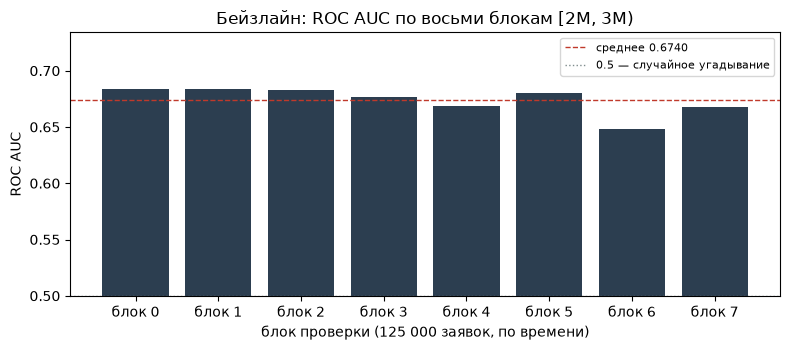


AUC выше 0.5 во всех блоках: True — уровни последней записи несут сигнал


In [6]:
eval_labels = labels[~fit_mask]
block_rows = []
for index, (start, stop) in enumerate(EVAL_BLOCKS):
    lo, hi = start - FIT_MAX, stop - FIT_MAX
    block_rows.append(
        {
            "блок": index,
            "id от": start,
            "id до": stop - 1,
            "заявок": hi - lo,
            "flag = 1": int(eval_labels[lo:hi].sum()),
            "AUC": float(roc_auc_score(eval_labels[lo:hi], proba[lo:hi])),
        }
    )
blocks = pd.DataFrame(block_rows)
mean_auc = float(blocks["AUC"].mean())
spread = float(blocks["AUC"].max() - blocks["AUC"].min())

print(blocks.assign(AUC=blocks["AUC"].round(4)).to_string(index=False))
sd_auc = float(blocks["AUC"].std(ddof=0))
naive_se = sd_auc / float(np.sqrt(len(blocks)))
print(f"\nсреднее AUC по блокам: {mean_auc:.4f}")
print(f"SD по блокам (ddof=0): {sd_auc:.4f}")
print(f"разброс по блокам (max − min): {spread:.4f}")
print(f"naive SE = SD / sqrt({len(blocks)}): {naive_se:.4f} — "
      "SE по 8 блокам — ориентир, а не доверительный интервал")
print(f"непустых блоков: {int((blocks['заявок'] == BLOCK_SIZE).sum())} из 8 по 125 000")

figure, axis = plt.subplots(figsize=(8, 3.6))
positions = np.arange(len(blocks))
axis.bar(positions, blocks["AUC"], color="#2c3e50")
axis.axhline(mean_auc, color="#c0392b", linestyle="--", linewidth=1, label=f"среднее {mean_auc:.4f}")
axis.axhline(0.5, color="#7f8c8d", linestyle=":", linewidth=1, label="0.5 — случайное угадывание")
axis.set_xticks(positions)
axis.set_xticklabels([f"блок {index}" for index in positions])
axis.set_xlabel("блок проверки (125 000 заявок, по времени)")
axis.set_ylabel("ROC AUC")
axis.set_ylim(0.5, float(blocks["AUC"].max()) + 0.05)
axis.set_title("Бейзлайн: ROC AUC по восьми блокам [2M, 3M)")
axis.legend(fontsize=8)
figure.tight_layout()
plt.show()

print(f"\nAUC выше 0.5 во всех блоках: {bool((blocks['AUC'] > 0.5).all())} — "
      "уровни последней записи несут сигнал")

## Что выучила линейная модель

У логистической регрессии коэффициент есть у каждой one-hot колонки. При
`drop=None` и L2-регуляризации в модели остаются все не-редкие уровни; уровни
с менее чем 500 заявками собраны в `infrequent`. Из-за коллинеарности (сумма
one-hot колонок признака связана с intercept) отдельные коэффициенты не
являются эффектами уровней. L2 дополнительно сжимает их к нулю. Топ-15 по
модулю — грубый ranking, а не причинный вывод.

Наибольший по модулю коэффициент — у `rn_1`: это one-hot колонка для `rn == 1`,
то есть для заявок с историей из одной записи. Положительный коэффициент
означает, что такие заявки связаны с более высокой долей `flag = 1` в этой
подгонке; это не эффект длины истории и не доказанное текущее состояние по всем
полям. У числового `rn` нет одного коэффициента: в one-hot модели у него
отдельные колонки, а абляция удаляет их все.


топ-15 коэффициентов по модулю:
              колонка one-hot  коэффициент  |коэффициент|
                         rn_1       0.7715         0.7715
pre_loans_credit_cost_rate_11      -0.5865         0.5865
 pre_loans_credit_cost_rate_6       0.5759         0.5759
      enc_loans_credit_type_0      -0.4908         0.4908
                   pre_util_4      -0.4858         0.4858
                         rn_2       0.4818         0.4818
                   pre_util_3       0.4217         0.4217
            is_zero_loans90_1      -0.4040         0.4040
                  pre_util_17       0.4037         0.4037
          pre_since_opened_12       0.3944         0.3944
             is_zero_loans5_1      -0.3624         0.3624
                         rn_3       0.3594         0.3594
                  pre_util_16      -0.3521         0.3521
           is_zero_loans530_1      -0.3503         0.3503
      enc_loans_credit_type_5       0.3497         0.3497

из 15 самых весомых колонок 0 — «сборна

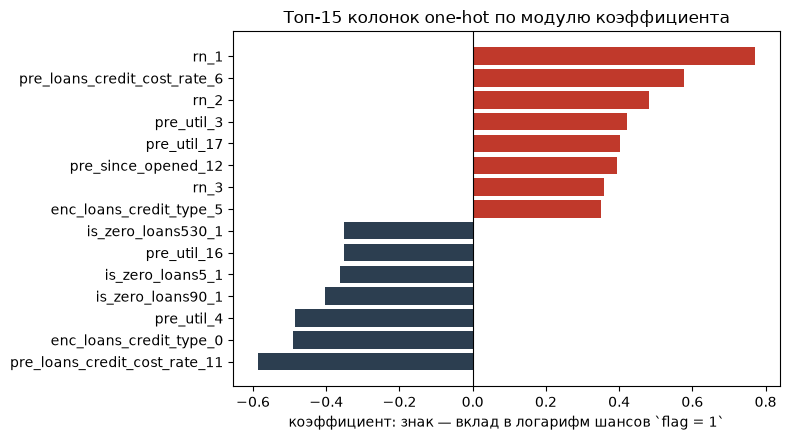

In [7]:
coefficients = pd.Series(model.coef_[0], index=FEATURE_NAMES)
top = coefficients[coefficients.abs().sort_values(ascending=False).index[:15]]
print("топ-15 коэффициентов по модулю:")
print(
    pd.DataFrame(
        {
            "колонка one-hot": top.index,
            "коэффициент": top.round(4).to_numpy(),
            "|коэффициент|": top.abs().round(4).to_numpy(),
        }
    ).to_string(index=False)
)

top_infrequent = int(sum("infrequent" in name for name in top.index))
print(f"\nиз 15 самых весомых колонок {top_infrequent} — «сборная солянка» infrequent")
print("знак: вклад в логарифм шансов `flag = 1` — плюс повышает шансы дефолта, минус понижает")

figure, axis = plt.subplots(figsize=(8, 4.5))
ordered = top.sort_values()
positions = np.arange(len(ordered))
colors = ["#c0392b" if value > 0 else "#2c3e50" for value in ordered.to_numpy()]
axis.barh(positions, ordered.to_numpy(), color=colors)
axis.set_yticks(positions)
axis.set_yticklabels(ordered.index)
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel("коэффициент: знак — вклад в логарифм шансов `flag = 1`")
axis.set_title("Топ-15 колонок one-hot по модулю коэффициента")
figure.tight_layout()
plt.show()

## Абляция `rn`

`rn` — номер последней записи, он же длина истории заявки; в one-hot модели у
него отдельные колонки, и наибольший модуль выше — у `rn_1` (история из одной
записи). Проверим, насколько AUC меняется при удалении этой величины: повторим
ту же схему без всех колонок `rn` и сравним AUC по тем же восьми блокам.
Считаем дельты
по блокам попарно (`с rn` минус `без rn`) и смотрим их среднее, SD и SE; блоки
коррелированы, поэтому это описательная статистика, а не тест значимости.


In [8]:
FEATURES_NO_RN = [name for name in FEATURES if name != "rn"]
encoder_no_rn = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=MIN_FREQUENCY,
    sparse_output=True,
    dtype=np.float32,
)
X_fit_no_rn = encoder_no_rn.fit_transform(applications.loc[fit_mask, FEATURES_NO_RN])
X_eval_no_rn = encoder_no_rn.transform(applications.loc[~fit_mask, FEATURES_NO_RN])
model_no_rn = LogisticRegression(solver="lbfgs", max_iter=MAX_ITER, random_state=SEED)
model_no_rn.fit(X_fit_no_rn, labels[fit_mask])
proba_no_rn = model_no_rn.predict_proba(X_eval_no_rn)[:, 1]
del X_fit_no_rn, X_eval_no_rn
_ = gc.collect()

ablation_rows = []
for index, (start, stop) in enumerate(EVAL_BLOCKS):
    lo, hi = start - FIT_MAX, stop - FIT_MAX
    auc_with_rn = float(roc_auc_score(eval_labels[lo:hi], proba[lo:hi]))
    auc_without_rn = float(roc_auc_score(eval_labels[lo:hi], proba_no_rn[lo:hi]))
    ablation_rows.append(
        {
            "блок": index,
            "AUC с rn": auc_with_rn,
            "AUC без rn": auc_without_rn,
            "дельта": auc_with_rn - auc_without_rn,
        }
    )
ablation = pd.DataFrame(ablation_rows)
mean_with_rn = float(ablation["AUC с rn"].mean())
mean_without_rn = float(ablation["AUC без rn"].mean())
paired = ablation["AUC с rn"] - ablation["AUC без rn"]
delta_rn = float(paired.mean())
paired_sd = float(paired.std(ddof=1))
paired_se = paired_sd / float(np.sqrt(len(paired)))

display_ablation = ablation.assign(
    **{column: ablation[column].round(4) for column in ("AUC с rn", "AUC без rn", "дельта")}
)
print(display_ablation.to_string(index=False))
print(f"\nабляция rn: с rn {mean_with_rn:.4f}, без rn {mean_without_rn:.4f}, дельта {delta_rn:.4f}")
print(f"парная SD дельт (ddof=1): {paired_sd:.4f}, парная SE: {paired_se:.4f}")
print(f"дельта положительна в {int((paired > 0).sum())} из {len(paired)} блоков — "
      "дельта = «с rn» минус «без rn»")

del applications
_ = gc.collect()

 блок  AUC с rn  AUC без rn  дельта
    0    0.6841      0.6772  0.0069
    1    0.6841      0.6798  0.0043
    2    0.6826      0.6761  0.0065
    3    0.6768      0.6764  0.0003
    4    0.6689      0.6656  0.0033
    5    0.6806      0.6775  0.0031
    6    0.6479      0.6505 -0.0026
    7    0.6675      0.6643  0.0032

абляция rn: с rn 0.6740, без rn 0.6709, дельта 0.0031
парная SD дельт (ddof=1): 0.0031, парная SE: 0.0011
дельта положительна в 7 из 8 блоков — дельта = «с rn» минус «без rn»


In [9]:
elapsed = time.perf_counter() - STARTED
print(f"пик памяти процесса: {peak_memory_gb():.2f} ГБ")
print(f"время прогона: {elapsed / 60:.1f} мин ({elapsed:.0f} с)")

пик памяти процесса: 4.31 ГБ
время прогона: 0.5 мин (30 с)


## Итог

**Точка отсчёта: среднее ROC AUC по восьми блокам `[2M, 3M)` = 0.6740.** Разброс по
блокам (максимум минус минимум) — 0.0362, SD по блокам (`ddof=0`) — 0.0116, наивный
`SE = SD / sqrt(8)` — 0.0041. Восемь блоков — это один временной отрезок и одно
разбиение, поэтому SE здесь — ориентир масштаба шума, а не доверительный интервал.

Что это значит:

- **Последняя запись + one-hot + логистическая регрессия.** Число задаёт точку отсчёта,
  а не порог: это уровень, который более сложное решение должно осмысленно превышать,
  а не граница «хорошо/плохо».
- **Что берём и чего нет.** Это «последняя запись как есть»: все сырые колонки последней
  записи. Среди них `rn` — номер последней записи, равный длине истории заявки, и
  абляция показывает изменение AUC при удалении `rn`: с `rn` — 0.6740,
  без `rn` — 0.6709, дельта — 0.0031, положительна в 7 из 8 блоков. Это небольшая
  положительная добавка: парная SD дельт (`ddof=1`) — 0.0031, парная
  SE — 0.0011. Блоки коррелированы, поэтому это описательная статистика, а не тест
  значимости. В решении нет:
  - агрегатов по всей истории (средних, экстремумов, смен уровней между записями);
  - динамики (как значения менялись от `rn = 1` к последней записи);
  - взаимодействий и нелинейностей (только сумма линейных вкладов уровней);
  - кодировки через цель (уровни равноправны, редкие свалены в `infrequent`).
- **Переход к `03`.** `02` и `03` используют один и тот же холдаут
  `[2 000 000, 3 000 000)` и те же восемь блоков по 125 000 заявок. Поэтому числа
  сопоставимы на одном отрезке, но разрыв нельзя приписывать одному изменению:
  в `03` одновременно меняются класс модели (линейная → бустинг), признаки
  (последняя запись → агрегаты по всей истории) и кодировка (one-hot → target
  encoding). Численное сравнение бейзлайна с бустингом приведено в README.
- **Калибровка.** Средняя вероятность на проверке (0.0341) близка к базовой доле
  (0.0341), но Brier score, logloss и calibration curve не считались; это не
  проверка калибровки.
- **Границы оценки.** 0.6740 — оценка на блоках train (`[2M, 3M)`), а не на test.
  Test не читался в `02`.

Почему такие настройки:

- `C=1.0` и L2 по умолчанию — регуляризация без подбора: задача раздела — планка «в лоб»,
  а не лучший линейный результат.
- `class_weight=None` — фактическая доля дефолтов (около 3.62% на обучении): редкий класс
  не получает перевес, и вероятности остаются сопоставимы с базовой частотой.
- Без масштабирования — все колонки бинарные `0/1`, масштабировать нечего.
- Полный one-hot без `drop='first'` плюс `intercept` — в модели остаются все
  не-редкие уровни; редкие собраны в `infrequent`. L2-регуляризация сжимает
  коэффициенты к нулю, а из-за коллинеарности отдельные коэффициенты не равны
  эффектам уровней.
- `min_frequency=500` — редкие уровни собраны в одну колонку `infrequent`: иначе уровень
  с парой заявок получил бы собственный коэффициент, неустойчивый при малом числе
  наблюдений.
- `seed` — для `lbfgs` это no-op (решатель детерминирован), параметр оставлен для
  совместимости.

Чего эта проверка не показывает:

- Один временной отрезок и восемь блоков: другой период или другое разбиение дадут
  другой разброс.
- Логистическая регрессия без подбора гиперпараметров: 0.6740 — не предел линейной
  модели, а одна конкретная конфигурация.
- Перенос на test: `02` не строит матрицу по test, планка считается на блоках train.
